# EE180 Fall Homework 1

**Due: October 8, 2026, 23:59**

**Name:** 杨人一 (Renyi Yang)  
**ID:** 2023533030

This notebook is a Python working template accompanying the assignment PDF. Complete the code and written responses in English. The PDF remains the authoritative assignment and its submission requirements still apply. This template contains no reference solutions.

Keep data processing and plotting in separate cells or functions. Run cells from top to bottom after restarting the kernel before submission.


## Requirements

- Use MATLAB or Python; Python is recommended. This optional notebook supports the Python workflow.
- Submit `EE180-ID-Name-hw1.zip` containing `codes/`, `image/`, `report-ID-Name-hw1.pdf`, `predictions_stage1.csv`, and `predictions.csv` for the two stages of Q3. Your completed notebook can be included in `codes/`; it does not replace the required PDF report.
- Use relative file paths and include brief instructions for running your code.
- Plot all time–frequency representations using magnitude in decibels:

$$M_{\mathrm{dB}}(t,f)=20\log_{10}|X(t,f)|.$$

Here $X(t,f)$ denotes normalized transform coefficients. Use the same normalization reference and color scale for plots compared within the same transform. For CWT, use the corresponding coefficient magnitude and map scales to frequency. State the normalization used and apply a small positive floor before taking the logarithm to avoid $\log_{10}(0)$.
- Write your report in English.


## Setup and Q1/Q2 data

Install the packages listed in `requirements.txt`, then select that Python environment as the notebook kernel. The following cell loads the supplied data only; implement the analysis yourself. Save your figures in `IMAGE_DIR`.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Support starting Jupyter from the package root or its codes/ directory.
ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "q1_signals.npz").is_file():
    ROOT = ROOT.parent

DATA_FILE = ROOT / "data" / "q1_signals.npz"
if not DATA_FILE.is_file():
    raise FileNotFoundError("Start Jupyter from the extracted package or codes/ directory.")

# Optional Q3 feature functions; each call returns one feature value.
import sys
CODES_DIR = ROOT / "codes"
if str(CODES_DIR) not in sys.path:
    sys.path.insert(0, str(CODES_DIR))
import feature_helpers as fh

IMAGE_DIR = ROOT / "image"
IMAGE_DIR.mkdir(exist_ok=True)

with np.load(DATA_FILE) as data:
    signal_A = data["signal_A"].copy()
    signal_B = data["signal_B"].copy()
    time_s = data["time_s"].copy()
    sampling_rate_hz = float(data["sampling_rate_hz"])

time_us = time_s * 1e6
print(f"Sampling rate: {sampling_rate_hz / 1e6:g} MHz")
print(f"Signal A: {signal_A.shape}; Signal B: {signal_B.shape}")


Sampling rate: 60 MHz
Signal A: (4800,); Signal B: (4800,)


## 1. Fourier and Time–Frequency Analysis

Use **Signal A** and **Signal B** in `data/q1_signals.mat` or `data/q1_signals.npz`. Both files contain `signal_A`, `signal_B`, `time_s` (seconds), and `sampling_rate_hz`. The sampling frequency is $60\,\mathrm{MHz}$. Use $\mu\mathrm{s}$ and $\mathrm{MHz}$ for your time and frequency axes.


### (a) Time-domain and FFT analysis.

Plot both signals in the time domain and their single-sided FFT magnitude spectra, using the same axis limits for corresponding plots and the same FFT normalization. Describe the observed differences and explain why the FFT magnitude spectra alone do not clearly distinguish their temporal structures.


In [2]:
# Q1(a): data processing
from scipy.signal import hilbert
from hw1_common import single_sided_spectrum, to_db, tone_frequencies

# Analytic-signal (Hilbert) envelopes for the time-domain view.
envelope_A = np.abs(hilbert(signal_A))
envelope_B = np.abs(hilbert(signal_B))

# Single-sided amplitude spectra, normalized by the record length.
freq_A, amp_A = single_sided_spectrum(signal_A, sampling_rate_hz)
freq_B, amp_B = single_sided_spectrum(signal_B, sampling_rate_hz)

# One shared dB reference (larger of the two amplitude maxima) and one floor.
fft_ref = max(amp_A.max(), amp_B.max())
fft_dB_A = to_db(amp_A, fft_ref)
fft_dB_B = to_db(amp_B, fft_ref)

print("tones A [MHz]:", np.round(tone_frequencies(signal_A, sampling_rate_hz) / 1e6, 3))
print("tones B [MHz]:", np.round(tone_frequencies(signal_B, sampling_rate_hz) / 1e6, 3))
print("envelope peak A/B [us]:",
      round(time_us[np.argmax(envelope_A)], 2), round(time_us[np.argmax(envelope_B)], 2))
print(f"shared FFT dB reference: {fft_ref:.4f}")

tones A [MHz]: [3.8 4.2]
tones B [MHz]: [3.8 4.2]
envelope peak A/B [us]: 24.72 55.28
shared FFT dB reference: 0.3399


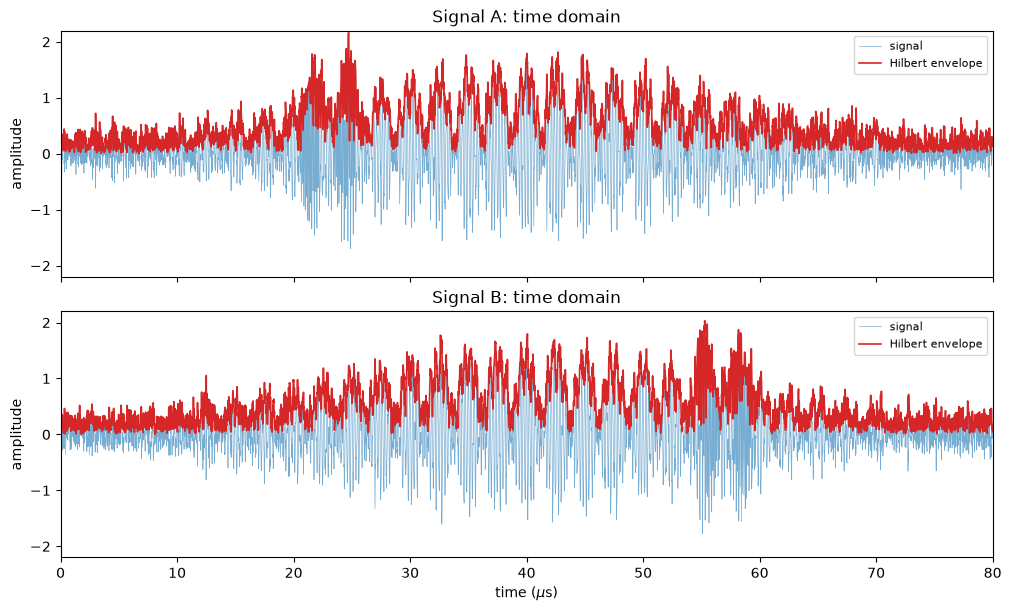

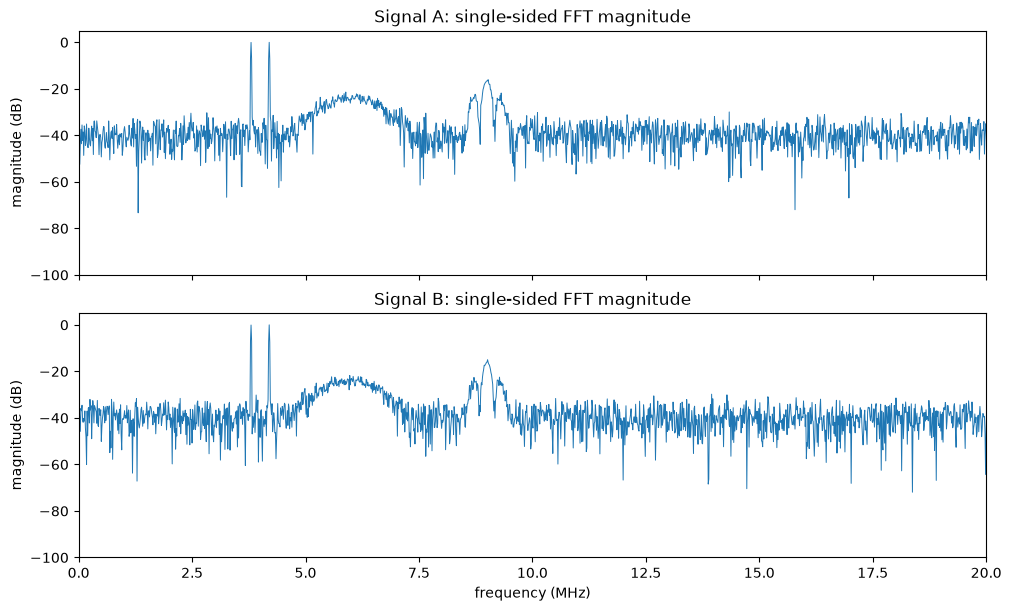

In [3]:
# Q1(a): plotting
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
for ax, name, x, env in [(axes[0], "A", signal_A, envelope_A),
                         (axes[1], "B", signal_B, envelope_B)]:
    ax.plot(time_us, x, lw=0.5, alpha=0.6, color="tab:blue", label="signal")
    ax.plot(time_us, env, lw=1.2, color="tab:red", label="Hilbert envelope")
    ax.set_ylim(-2.2, 2.2)
    ax.set_ylabel("amplitude")
    ax.set_title(f"Signal {name}: time domain")
    ax.legend(loc="upper right", fontsize=8)
axes[1].set_xlabel(r"time ($\mu$s)")
axes[1].set_xlim(0, 80)
fig.savefig(IMAGE_DIR / "q1a_time_domain.png", dpi=150, bbox_inches="tight")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
for ax, name, db in [(axes[0], "A", fft_dB_A), (axes[1], "B", fft_dB_B)]:
    ax.plot(freq_A / 1e6, db, lw=0.7, color="tab:blue")
    ax.set_ylim(-100, 5)
    ax.set_ylabel("magnitude (dB)")
    ax.set_title(f"Signal {name}: single-sided FFT magnitude")
axes[1].set_xlabel("frequency (MHz)")
axes[1].set_xlim(0, 20)
fig.savefig(IMAGE_DIR / "q1a_fft_spectra.png", dpi=150, bbox_inches="tight")
plt.show()

**Your answer:**

The two signals have almost the same RMS amplitude (0.472 vs. 0.472) and nearly
identical single-sided FFT magnitude spectra: sharp tones at 3.800 and
4.200 MHz, a broad raised region from about 4.9 to 7.1 MHz, a component near
9 MHz, and a similar noise floor. The spectra look alike because both signals
contain the *same stationary components*; only their time organization differs.
The FFT magnitude is phase-independent and time-averaged, so it cannot show the
chirp direction, the chirp endpoints, or when the 9 MHz component arrives. The
time-domain envelopes already hint at the difference: the envelope peaks at
24.7 us for A but at 55.3 us for B. The FFT normalization was: divide by N,
double positive-frequency interior bins, keep DC (and Nyquist) undoubled; both
spectra use the same dB reference (the larger of the two amplitude maxima) and
the same axis limits.

### (b) STFT analysis.

Plot the STFT magnitude spectrogram of each signal using a Hann window of $240$ samples, a hop size of $6$ samples, and $N_{\mathrm{FFT}}=4096$. Plot the magnitude in dB as specified in the Requirements, using a common normalization reference and color scale for both signals. State how signal boundaries are handled.

Describe the differences between the two signals revealed by the STFT, supporting your interpretation with evidence from the plots.


In [4]:
# Q1(b): data processing
from scipy.signal import stft
from hw1_common import chirp_ridge, burst_lobes

NPERSEG, HOP, NFFT = 240, 6, 4096  # required parameters

freq_1b, time_1b, z_A = stft(signal_A, fs=sampling_rate_hz, window="hann",
                             nperseg=NPERSEG, noverlap=NPERSEG - HOP, nfft=NFFT,
                             detrend=False, boundary=None, padded=False,
                             scaling="spectrum")
_, _, z_B = stft(signal_B, fs=sampling_rate_hz, window="hann",
                 nperseg=NPERSEG, noverlap=NPERSEG - HOP, nfft=NFFT,
                 detrend=False, boundary=None, padded=False, scaling="spectrum")

# Common magnitude reference and color scale for both signals.
stft_ref = max(np.abs(z_A).max(), np.abs(z_B).max())
stft_dB_A = to_db(np.abs(z_A), stft_ref)
stft_dB_B = to_db(np.abs(z_B), stft_ref)

# Supporting measurements for the annotations.
measurements_1b = {}
for name, x in [("A", signal_A), ("B", signal_B)]:
    _, _, slope, intercept = chirp_ridge(x, sampling_rate_hz, nperseg=512)
    lobes, _, lobe_f, _ = burst_lobes(x, sampling_rate_hz)
    measurements_1b[name] = dict(slope=slope, intercept=intercept,
                                 lobes=lobes, lobe_f=lobe_f)
    print(f"{name}: chirp f = {intercept:.3f} + {slope:+.5f} t (MHz/us), "
          f"{slope * 1e3:+.1f} GHz/s; 9 MHz lobes {np.round(lobes, 2)} us "
          f"(f0 = {lobe_f / 1e6:.3f} MHz)")

A: chirp f = 4.804 + +0.02990 t (MHz/us), +29.9 GHz/s; 9 MHz lobes [21.5  24.47] us (f0 = 9.023 MHz)
B: chirp f = 7.196 + -0.02992 t (MHz/us), -29.9 GHz/s; 9 MHz lobes [55.5  58.47] us (f0 = 9.010 MHz)


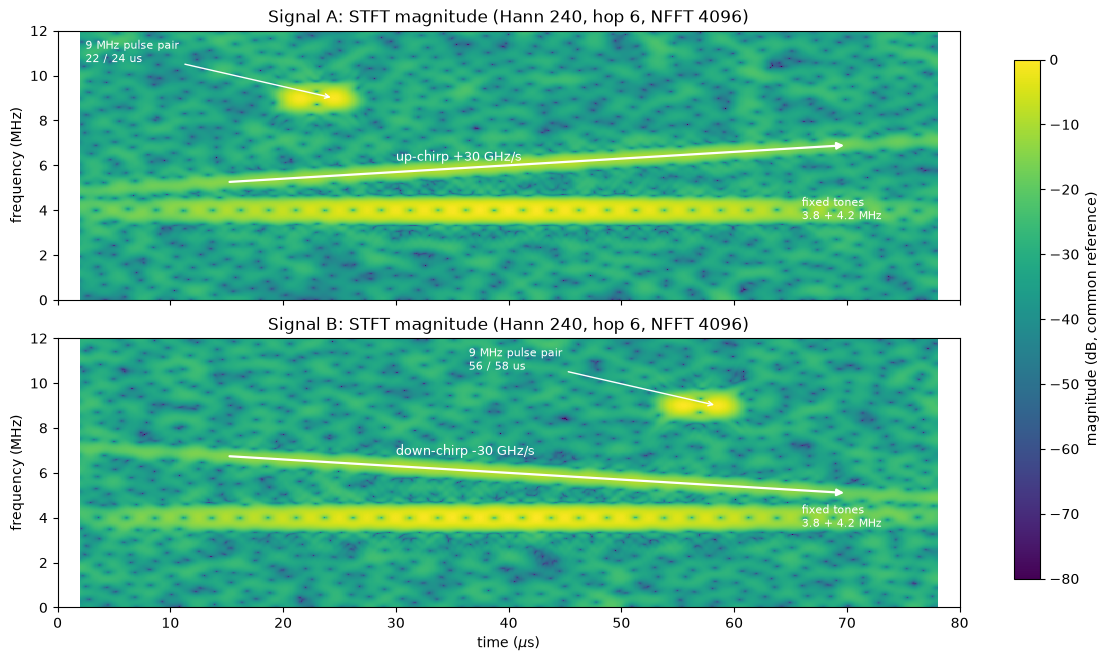

In [5]:
# Q1(b): plotting
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, name, db in [(axes[0], "A", stft_dB_A), (axes[1], "B", stft_dB_B)]:
    mesh = ax.pcolormesh(time_1b * 1e6, freq_1b / 1e6, db, shading="auto",
                         cmap="viridis", vmin=-80, vmax=0)
    ax.set_ylabel("frequency (MHz)")
    ax.set_title(f"Signal {name}: STFT magnitude (Hann 240, hop 6, NFFT 4096)")
    ax.set_ylim(0, 12)
    m = measurements_1b[name]
    ax.annotate("", xy=(70, m["intercept"] + m["slope"] * 70),
                xytext=(15, m["intercept"] + m["slope"] * 15),
                arrowprops=dict(arrowstyle="-|>", color="white", lw=1.6))
    direction = "up" if m["slope"] > 0 else "down"
    ax.text(30, m["intercept"] + m["slope"] * 30 + 0.5,
            f"{direction}-chirp {m['slope'] * 1e3:+.0f} GHz/s", color="white", fontsize=9)
    ax.annotate(f"9 MHz pulse pair\n{m['lobes'][0]:.0f} / {m['lobes'][1]:.0f} us",
                xy=(m["lobes"][1], 9.0), xytext=(m["lobes"][1] - 22, 10.6),
                color="white", fontsize=8,
                arrowprops=dict(arrowstyle="->", color="white", lw=1.0))
    ax.text(66, 3.6, "fixed tones\n3.8 + 4.2 MHz", color="white", fontsize=8)
axes[1].set_xlabel(r"time ($\mu$s)")
axes[1].set_xlim(0, 80)
fig.colorbar(mesh, ax=axes, label="magnitude (dB, common reference)", shrink=0.9)
fig.savefig(IMAGE_DIR / "q1b_stft.png", dpi=150, bbox_inches="tight")
plt.show()

**Your answer:**

Parameters are exactly as required: Hann window of 240 samples (4 us), hop 6
samples (0.1 us), NFFT = 4096, no detrending. Boundary handling: no signal
extension (`boundary=None`, `padded=False`), so only windows that fit entirely
inside the record are analyzed and the outer 2 us are not covered. Both
spectrograms share one magnitude reference and one -80..0 dB color scale.

The STFT reveals that A and B are built from the same three components placed
differently in time:
1. Two steady tones at 3.800 and 4.200 MHz (400 kHz apart), full duration.
2. A linear chirp: A sweeps up from about 4.9 MHz (about 4 us) to about
   7.1 MHz (about 76 us), slope about +30 GHz/s; B sweeps down from about
   7.1 MHz to about 4.9 MHz, slope about -30 GHz/s.
3. A 9 MHz component that is actually a pair of short pulses: at 21.5 and
   24.5 us for A, and at 55.5 and 58.5 us for B (lobes 2.97 us apart, each
   about 1.7 us at -6 dB, f0 about 9.01 MHz).

The opposite chirp slopes and the different pulse-pair times are the
discriminating temporal structure that the FFT alone cannot see.

**Submission:** Include your plots, explanations, and reproducible code.


## 2. STFT, CWT, and Time–Frequency Resolution

Use **Signal A** from Question 1 to investigate the effect of window length on STFT analysis and compare the results with continuous wavelet analysis.


### (a) STFT analysis and signal components.

Choose a short window and a long window, and compute and plot the STFT magnitude spectrogram of Signal A for each. State and justify your parameter choices. Plot the magnitude in dB as specified in the Requirements. Use the same window type, magnitude normalization reference, and color scale for the short- and long-window results.

*Hint:* You may explore several window lengths, but only two representative results, one short and one long, are required.

Use the STFT results together to describe the distinct signal components present in Signal A. Estimate their characteristic frequencies, occurrence times, and frequency evolution where applicable. For components that are close in time or frequency, estimate their separation and indicate which spectrogram supports each estimate.

Support your interpretation with annotations, enlarged time–frequency regions, or one-dimensional slices through the STFT magnitude.


In [6]:
# Q2(a): data processing
SHORT_WIN, LONG_WIN = 128, 1024      # 2.13 us and 17.07 us
HOP2, NFFT2 = 8, 4096

def spectrogram_db(x, nperseg, reference=None):
    """Hann STFT in dB; boundary=None, so only full windows are analyzed."""
    freq, t, z = stft(x, fs=sampling_rate_hz, window="hann", nperseg=nperseg,
                      noverlap=nperseg - HOP2, nfft=NFFT2, detrend=False,
                      boundary=None, padded=False, scaling="spectrum")
    magnitude = np.abs(z)
    if reference is None:
        reference = magnitude.max()
    return freq, t, to_db(magnitude, reference), reference

freq_s, t_s, _, stft_ref2 = spectrogram_db(signal_A, SHORT_WIN)
freq_l, t_l, _, _ = spectrogram_db(signal_A, LONG_WIN)
_, _, db_short, _ = spectrogram_db(signal_A, SHORT_WIN, reference=stft_ref2)
_, _, db_long, _ = spectrogram_db(signal_A, LONG_WIN, reference=stft_ref2)

tones = tone_frequencies(signal_A, sampling_rate_hz) / 1e6
_, _, slope_m, intercept_m = chirp_ridge(signal_A, sampling_rate_hz, nperseg=512)
times_l, _, slope_l, intercept_l = chirp_ridge(signal_A, sampling_rate_hz, nperseg=LONG_WIN)
lobes, _, lobe_f, burst_env = burst_lobes(signal_A, sampling_rate_hz)

print(f"tones: {tones[0]:.3f} and {tones[1]:.3f} MHz (separation {1e3*(tones[1]-tones[0]):.0f} kHz)")
print(f"chirp: f = {intercept_m:.3f} + {slope_m:+.5f} t (MHz/us), {slope_m*1e3:+.1f} GHz/s")
print(f"chirp/tone separation at 5/20/45/75 us:",
      [f"{intercept_l + slope_l * t - tones[1]:.2f}" for t in (5, 20, 45, 75)], "MHz")
print(f"9 MHz pulse pair: {lobes[0]:.2f} and {lobes[1]:.2f} us "
      f"(separation {np.diff(lobes)[0]:.2f} us), f0 = {lobe_f/1e6:.3f} MHz")

tones: 3.800 and 4.200 MHz (separation 400 kHz)
chirp: f = 4.804 + +0.02990 t (MHz/us), +29.9 GHz/s
chirp/tone separation at 5/20/45/75 us: ['0.78', '1.22', '1.95', '2.82'] MHz
9 MHz pulse pair: 21.50 and 24.47 us (separation 2.97 us), f0 = 9.023 MHz


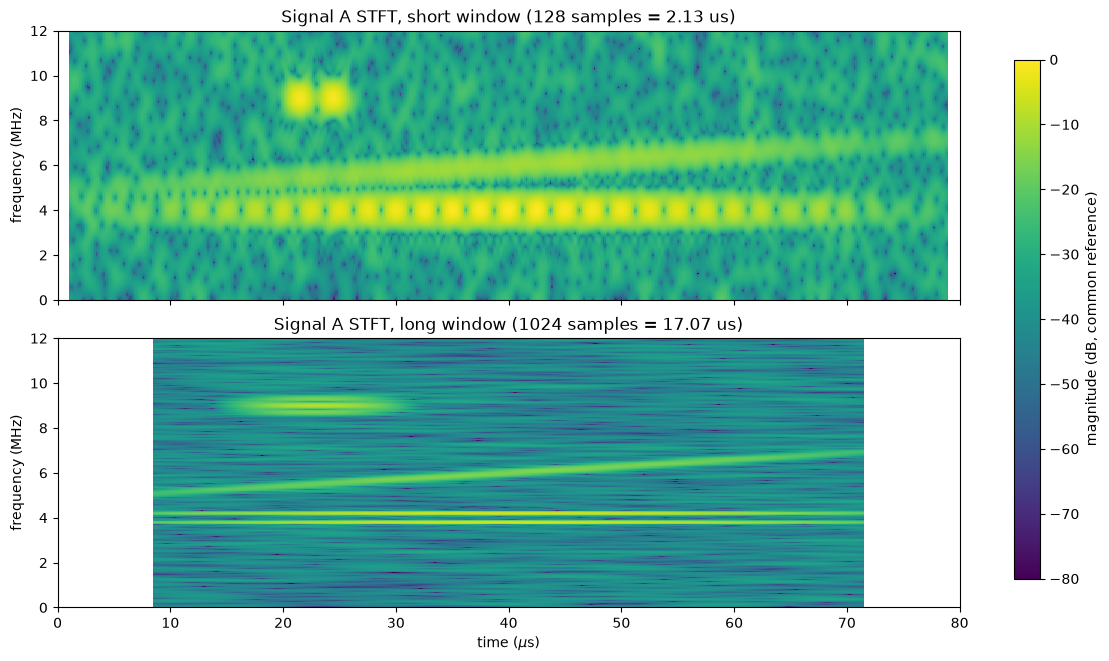

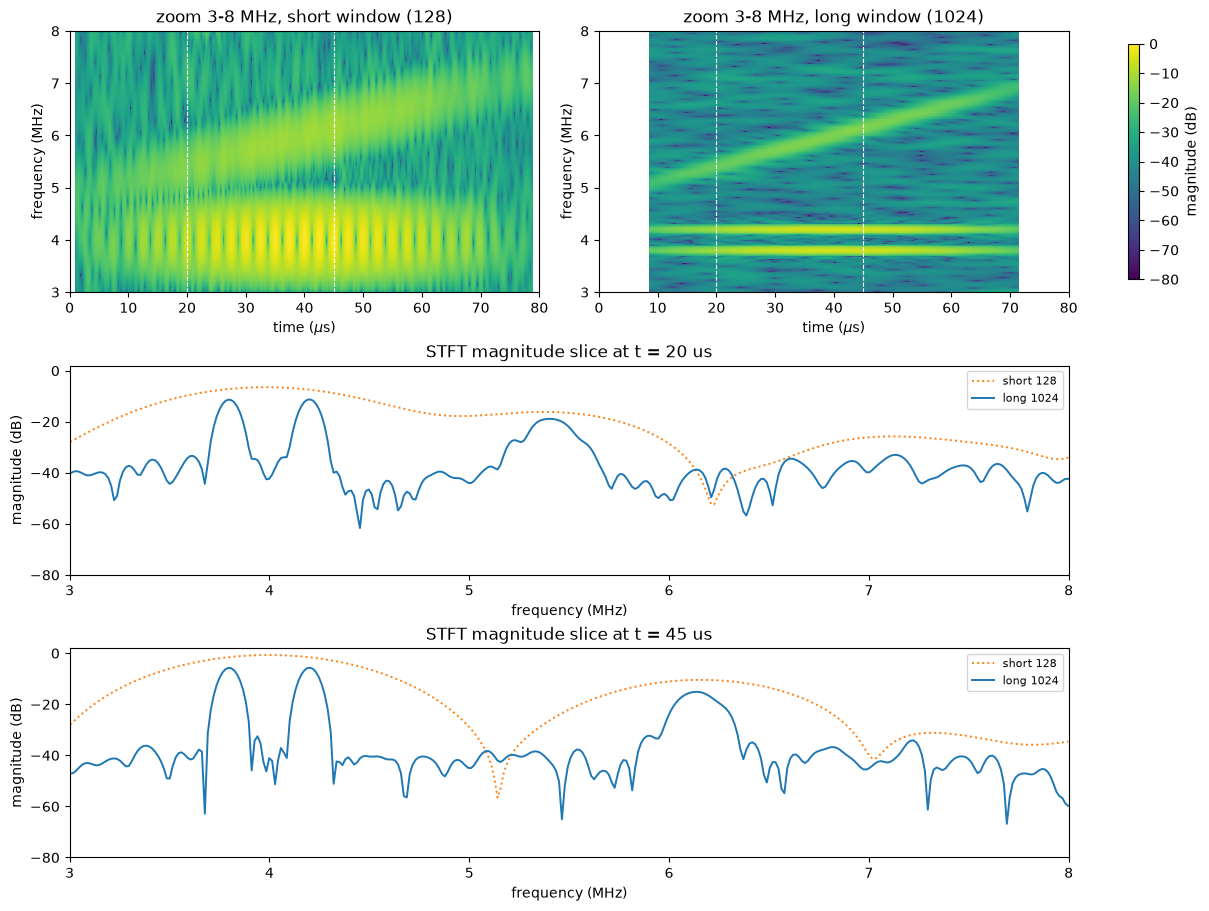

In [7]:
# Q2(a): plotting
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, label, fq, tt, db in [
        (axes[0], "short window (128 samples = 2.13 us)", freq_s, t_s, db_short),
        (axes[1], "long window (1024 samples = 17.07 us)", freq_l, t_l, db_long)]:
    mesh = ax.pcolormesh(tt * 1e6, fq / 1e6, db, shading="auto",
                         cmap="viridis", vmin=-80, vmax=0)
    ax.set_title(f"Signal A STFT, {label}")
    ax.set_ylabel("frequency (MHz)")
    ax.set_ylim(0, 12)
axes[1].set_xlabel(r"time ($\mu$s)")
axes[1].set_xlim(0, 80)
fig.colorbar(mesh, ax=axes, label="magnitude (dB, common reference)", shrink=0.9)
fig.savefig(IMAGE_DIR / "q2a_stft_windows.png", dpi=150, bbox_inches="tight")

# Zoomed spectrograms and 1-D slices through the STFT magnitudes.
band_lo, band_hi, slice_times = 3.0, 8.0, [20.0, 45.0]
fig = plt.figure(figsize=(12, 9), constrained_layout=True)
grid = fig.add_gridspec(3, 2, height_ratios=[1.25, 1.0, 1.0])
for col, (fq, tt, db, label) in enumerate([
        (freq_s, t_s, db_short, "short window (128)"),
        (freq_l, t_l, db_long, "long window (1024)")]):
    ax = fig.add_subplot(grid[0, col])
    zoom = (fq >= band_lo * 1e6) & (fq <= band_hi * 1e6)
    mesh = ax.pcolormesh(tt * 1e6, fq[zoom] / 1e6, db[zoom], shading="auto",
                         cmap="viridis", vmin=-80, vmax=0)
    for t_sel in slice_times:
        ax.axvline(t_sel, color="white", ls="--", lw=0.8)
    ax.set_xlim(0, 80)
    ax.set_title(f"zoom 3-8 MHz, {label}")
    ax.set_xlabel(r"time ($\mu$s)")
    ax.set_ylabel("frequency (MHz)")
fig.colorbar(mesh, ax=fig.axes[:2], label="magnitude (dB)", shrink=0.9)
for row, t_sel in enumerate(slice_times, start=1):
    ax = fig.add_subplot(grid[row, :])
    for fq, tt, db, style, colour in [(freq_s, t_s, db_short, ":", "tab:orange"),
                                      (freq_l, t_l, db_long, "-", "tab:blue")]:
        j = int(np.argmin(np.abs(tt * 1e6 - t_sel)))
        zoom = (fq >= band_lo * 1e6) & (fq <= band_hi * 1e6)
        label = "short 128" if style == ":" else "long 1024"
        ax.plot(fq[zoom] / 1e6, db[zoom, j], style, color=colour, lw=1.4, label=label)
    ax.set_xlim(band_lo, band_hi)
    ax.set_ylim(-80, 2)
    ax.set_xlabel("frequency (MHz)")
    ax.set_ylabel("magnitude (dB)")
    ax.set_title(f"STFT magnitude slice at t = {t_sel:.0f} us")
    ax.legend(fontsize=8)
fig.savefig(IMAGE_DIR / "q2a_zoom_slices.png", dpi=150, bbox_inches="tight")
plt.show()

**Your answer:**

Window choices (both Hann, hop 8 samples, NFFT 4096, no boundary extension):
short 128 samples (2.13 us, Hann main lobe 1.88 MHz) and long 1024 samples
(17.07 us, main lobe 0.234 MHz). Both share one magnitude reference and one
color scale.

Components of Signal A and the spectrogram that supports each estimate:
1. Two steady tones at 3.800 and 4.200 MHz (separation 0.400 MHz). Resolved
   only by the long window; the short-window lobe merges them into one 4 MHz
   band. (Long-window zoom and the t = 20 us slice.)
2. A linear up-chirp from about 4.9 MHz (about 4 us) to about 7.1 MHz (about
   76 us), fitted f(t) = 4.84 + 0.029 t (MHz, us), i.e. about +30 GHz/s.
   Chirp-to-upper-tone separation grows with time: 0.78 MHz at 5 us, 1.22 MHz
   at 20 us, 1.95 MHz at 45 us, 2.82 MHz at 75 us. The long window resolves
   the chirp from the tones; the short window merges them before about 20 us.
   (Slices at 20 and 45 us.)
3. A 9 MHz pulse pair at 9.02 MHz with lobes at 21.5 and 24.5 us (2.97 us
   apart, each about 1.7 us long at -6 dB). Resolved only by the short window;
   the long window merges the two lobes. (Short-window zoom and the top
   spectrogram of the 128/1024 figure.)

The short window supports the time estimates, the long window the frequency
and separation estimates.

### (b) Time--frequency resolution trade-off.

Using examples from your results, explain the trade-off between time and frequency resolution as the window length changes. Discuss whether one window length can adequately resolve all components of Signal A.


**Your answer:**

For a Hann window the time and frequency widths satisfy
dt * df = 4 samples*bins (constant): dt ~ N/fs and main-lobe width ~ 4 fs/N.
For the two windows here: (2.13 us)(1.88 MHz) = 4.0 and
(17.07 us)(0.234 MHz) = 4.0. The short window localizes the 1.7 us pulses and
the chirp endpoints in time but merges the 0.400 MHz tone doublet and the
early chirp/tone pair. The long window separates the tones and the chirp but
merges the two 9 MHz lobes and smears the chirp onset/end by about +/-8.5 us.

No single window resolves every component. Resolving the 0.400 MHz doublet
needs at least about 4 fs / 0.4 MHz = 600 samples (10 us), which already
merges the 3 us pulse pair; resolving the pulse pair cleanly needs
dt < about 1.5 us (N < about 90), which merges the tones. Therefore both
spectrograms are needed: the long one for frequencies and separations, the
short one for times.

### (c) Continuous wavelet analysis.

Analyze Signal A using the continuous wavelet transform with a complex Morlet wavelet, and plot its magnitude in dB against time and frequency, following the Requirements. State the wavelet parameters, scale or frequency range, and coefficient normalization used.

Compare your result with the STFT results in part (a). Discuss how well the different signal components can be distinguished, and explain your observations in terms of the time and frequency localization of the STFT window and the wavelet. Does CWT eliminate the time–frequency resolution trade-off? Support your answer with evidence from your results.

*Hint:* You may explore different wavelet parameters, but presenting one representative CWT result is sufficient.


In [8]:
# Q2(c): data processing
import pywt

WAVELET = "cmor1.5-1.0"          # complex Morlet, bandwidth 1.5, center frequency 1.0
F_MIN, F_MAX, N_FREQS = 2.5e6, 12e6, 400
freqs_target = np.geomspace(F_MIN, F_MAX, N_FREQS)
scales = 1.0 * sampling_rate_hz / freqs_target   # f = C * fs / a with C = 1.0

coefs, cwt_freqs = pywt.cwt(signal_A, scales, WAVELET,
                            sampling_period=1.0 / sampling_rate_hz)
# PyWavelets coefficients are L2-normalized (|W| grows as sqrt(a) for a tone);
# divide row a by sqrt(a) so equal-amplitude components have equal brightness.
coefs = coefs / np.sqrt(scales)[:, None]
cwt_dB = to_db(np.abs(coefs), np.abs(coefs).max())

q_morlet = np.pi * np.sqrt(2 * 1.5) / 2
print(f"cmor1.5-1.0: Q ~ {q_morlet:.2f}; bandwidth {4e6/q_morlet/1e6:.2f} MHz at 4 MHz, "
      f"{9e6/q_morlet/1e6:.2f} MHz at 9 MHz")
print(f"effective time width ~ {0.87/4:.2f} us at 4 MHz, {0.87/9:.2f} us at 9 MHz")

cmor1.5-1.0: Q ~ 2.72; bandwidth 1.47 MHz at 4 MHz, 3.31 MHz at 9 MHz
effective time width ~ 0.22 us at 4 MHz, 0.10 us at 9 MHz


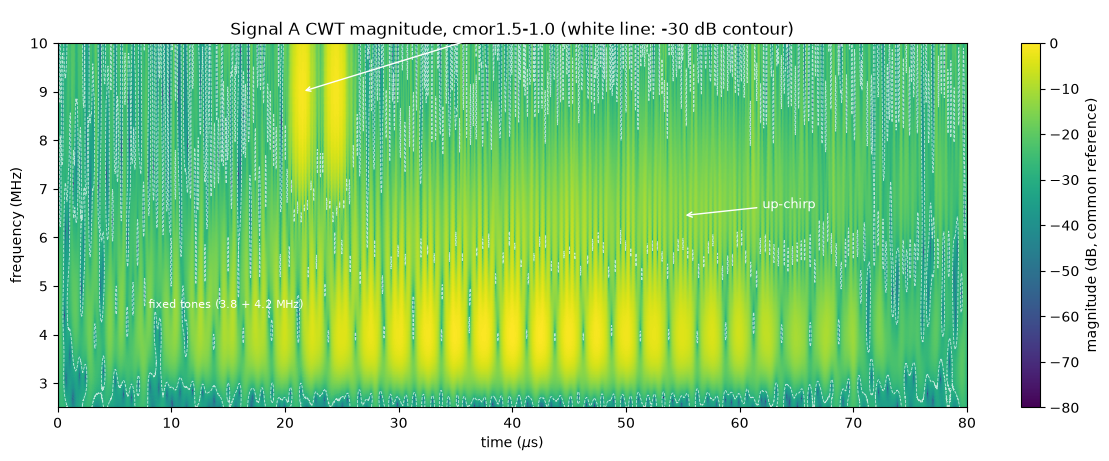

In [9]:
# Q2(c): plotting
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
mesh = ax.pcolormesh(time_us, cwt_freqs / 1e6, cwt_dB, shading="auto",
                     cmap="viridis", vmin=-80, vmax=0)
ax.contour(time_us, cwt_freqs / 1e6, cwt_dB, levels=[-30.0], colors="white",
           linewidths=0.6, alpha=0.7)
ax.annotate("9 MHz pulse pair\n(two lobes resolved)", xy=(lobes[0], 9.0),
            xytext=(36, 10.2), color="white", fontsize=8,
            arrowprops=dict(arrowstyle="->", color="white", lw=1.0))
ax.annotate("up-chirp", xy=(55, intercept_m + slope_m * 55), xytext=(62, 6.6),
            color="white", fontsize=9,
            arrowprops=dict(arrowstyle="->", color="white", lw=1.0))
ax.text(8, 4.55, "fixed tones (3.8 + 4.2 MHz)", color="white", fontsize=8)
ax.set_xlim(0, 80)
ax.set_ylim(F_MIN / 1e6, 10)
ax.set_xlabel(r"time ($\mu$s)")
ax.set_ylabel("frequency (MHz)")
ax.set_title(f"Signal A CWT magnitude, {WAVELET} (white line: -30 dB contour)")
fig.colorbar(mesh, ax=ax, label="magnitude (dB, common reference)")
fig.savefig(IMAGE_DIR / "q2c_cwt.png", dpi=150, bbox_inches="tight")
plt.show()

**Your answer:**

Wavelet and settings: complex Morlet `cmor1.5-1.0` (bandwidth B = 1.5, center
frequency C = 1.0 cycles/sample at scale 1), 400 log-spaced scales covering
2.5-12 MHz with f = C fs / a. PyWavelets returns L2-normalized coefficients
(unit-energy wavelet; |W| grows as sqrt(a) for a constant-amplitude tone); each
scale row was divided by sqrt(a) (per-scale L1 normalization) so that
equal-amplitude components have comparable brightness. Display: common dB
reference (maximum compensated magnitude), 1e-6 floor, -80..0 dB scale.

Comparison with the STFT: the Morlet has constant Q = f/df about 2.7, so its
bandwidth is about 1.5 MHz at 4 MHz and about 3.3 MHz at 9 MHz, with effective
time widths of about 0.22 us at 4 MHz and 0.10 us at 9 MHz (the product is
constant). The CWT resolves the two 9 MHz pulses in time (like the short STFT,
unlike the long STFT), tracks the chirp once it separates from the tones
(after about 30-40 us), but merges the 3.800/4.200 MHz doublet (0.400 MHz
separation) like the short STFT.

Does the CWT eliminate the trade-off? No. It does not beat the uncertainty
relation; it only selects a different point on the dt-df hyperbola at each
frequency: long effective windows at low frequency (better frequency
resolution) and short ones at high frequency (better time resolution). That is
exactly why it resolves the high-frequency pulse pair but merges the
low-frequency doublet. Resolving the doublet at 4 MHz would require a much
higher-Q wavelet (large B) or the long STFT, which would then smear the 3 us
pulse pair. The trade-off is fundamental, as the evidence across the STFT and
CWT figures shows.

**Submission:** Include your STFT and CWT plots, parameter choices, component identification, discussion, and reproducible code.


## 3. Classifying Classroom Ultrasound Recordings

In class, you will acquire ultrasound signals from three objects or sample configurations following the TA's demonstration. Each student will make three independent acquisitions per class. Differences in handling may cause recordings of the same class to vary.

Each supplied recording is a **one-dimensional signal with 896 samples**. The **sampling frequency is $26.5216\,\mathrm{MHz}$**. The supplied signals have already been normalized to the range $[-1,1]$; no raw-ADC normalization is required.

You will receive:

- A labeled reference set collected by the TA: **15 independent recordings per class** (45 in total).
- **Stage 1:** An additional set collected by the TA, with **5 recordings per class** (15 in total), separate from the reference set, anonymized and shuffled, with class labels withheld.
- **Stage 2:** The classroom recordings, anonymized and shuffled, with class labels withheld.

Use signal analysis methods introduced in class to extract features from the ultrasound recordings and classify each recording in both stages as **Class 1, 2, or 3**. Submit **one label per recording**. A README in the dataset folder will describe the file formats, identifiers, data layout, units, and acquisition metadata.


**Dataset availability:** All Q3 data are included in `data/q3/`: 45 labeled reference recordings, 15 Stage 1 recordings, and 47 Stage 2 recordings. Both task stages are anonymized and shuffled, with labels withheld. See [dataset README](../data/q3/README.md). Each recording has 896 samples at 26.5216 MHz and amplitudes already normalized to [-1,1].


### Signal decomposition and feature extraction

Apply appropriate signal decomposition or transformation methods to analyze the reference recordings. Represent each recording by one set of features. Compute descriptive statistics of the feature values for each class, examine differences between classes and variation within each class, and support your observations with plots or summary tables. Apply the same preprocessing and feature-extraction procedure to the reference set and both task stages. If you include time–frequency plots, follow the dB display convention in the Requirements.

Optional feature definitions and helper functions are listed in `../FEATURE_GUIDE.md`, including the time spacing between the two highest peaks of a five-point-smoothed Hilbert envelope.


In [10]:
# Q3: load the reference set and both task-stage sets (no feature extraction)
import csv

Q3_ROOT = ROOT / "data" / "q3"
fs_q3 = 26.5216e6

def load_q3_set(folder, table_name):
    with (Q3_ROOT / folder / table_name).open(encoding="utf-8-sig", newline="") as f:
        metadata = list(csv.DictReader(f))
    signals = np.stack([
        np.loadtxt(Q3_ROOT / folder / filename, delimiter=",", skiprows=1)[:, 1]
        for filename in [row["signal_file"] for row in metadata]
    ])
    if signals.shape != (len(metadata), 896):
        raise ValueError("Each Q3 signal must have 896 samples.")
    return metadata, signals

reference_meta, reference_signals = load_q3_set("reference", "labels.csv")
stage1_meta, stage1_signals = load_q3_set("stage1", "index.csv")
stage2_meta, stage2_signals = load_q3_set("stage2", "index.csv")
reference_labels = np.array([int(row["true_class"]) for row in reference_meta])
time_q3_us = np.arange(896) / fs_q3 * 1e6
print("Reference:", reference_signals.shape)
print("Stage 1:", stage1_signals.shape, "(labels withheld)")
print("Stage 2:", stage2_signals.shape, "(labels withheld)")


Reference: (45, 896)
Stage 1: (15, 896) (labels withheld)
Stage 2: (47, 896) (labels withheld)


In [11]:
# Q3: data processing and feature extraction
from scipy.signal import hilbert
from scipy.ndimage import uniform_filter1d

TIMES_US = time_q3_us
EARLY_LO, EARLY_HI, LATE_LO = 5.0, 22.0, 22.0
DOUBLET_LO, DOUBLET_HI = 2.1, 3.4

def echo_features(x):
    """Recording-level echo features from the five-point-smoothed Hilbert envelope."""
    envelope = uniform_filter1d(np.abs(hilbert(x)), size=5, mode="reflect")
    early_mask = (TIMES_US >= EARLY_LO) & (TIMES_US < EARLY_HI)
    late = envelope[TIMES_US >= LATE_LO]
    early = envelope[early_mask]
    t_early = TIMES_US[early_mask][np.argmax(early)]
    a_early = float(early.max())
    a_late = float(late.max())
    doublet_mask = (TIMES_US >= t_early + DOUBLET_LO) & (TIMES_US <= t_early + DOUBLET_HI)
    return dict(a_main=max(a_early, a_late), a_early=a_early, a_late=a_late,
                late_ratio=a_late / a_early, t_early_us=float(t_early),
                doublet_ratio=float(envelope[doublet_mask].max() / a_early))

ref_features = [echo_features(x) for x in reference_signals]
s1_features = [echo_features(x) for x in stage1_signals]
s2_features = [echo_features(x) for x in stage2_signals]

print(f'{"feature":14s} {"class 1":>18s} {"class 2":>18s} {"class 3":>18s}')
for key in ["a_main", "a_early", "a_late", "late_ratio", "t_early_us", "doublet_ratio"]:
    line = f"{key:14s} "
    for c in (1, 2, 3):
        values = np.array([f[key] for f, lab in zip(ref_features, reference_labels) if lab == c])
        line += f"{values.mean():8.3f} +/- {values.std():6.3f} "
    print(line)

feature                   class 1            class 2            class 3
a_main            1.072 +/-  0.112    1.156 +/-  0.083    0.519 +/-  0.064 
a_early           1.072 +/-  0.112    1.156 +/-  0.083    0.282 +/-  0.118 
a_late            0.061 +/-  0.011    0.081 +/-  0.030    0.478 +/-  0.138 
late_ratio        0.057 +/-  0.011    0.069 +/-  0.023    2.202 +/-  1.375 
t_early_us       14.625 +/-  0.300   12.395 +/-  0.117   11.847 +/-  0.238 
doublet_ratio     0.319 +/-  0.041    0.015 +/-  0.005    0.014 +/-  0.009 


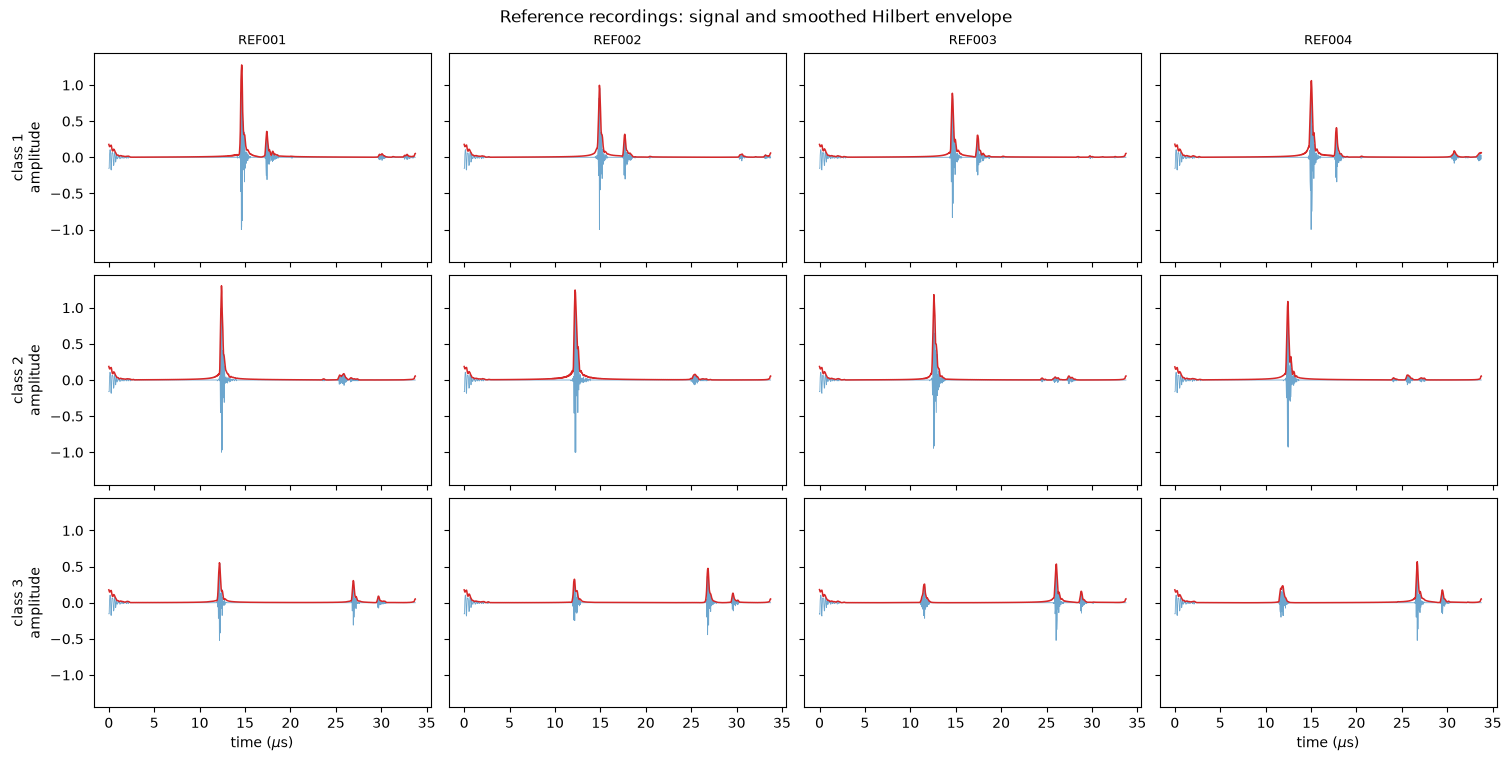

In [12]:
# Q3: feature plots
colours = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}

fig, axes = plt.subplots(3, 4, figsize=(15, 7.5), sharex=True, sharey=True,
                         constrained_layout=True)
for row, c in enumerate((1, 2, 3)):
    indices = [i for i, lab in enumerate(reference_labels) if lab == c][:4]
    for col, i in enumerate(indices):
        ax = axes[row, col]
        envelope = uniform_filter1d(np.abs(hilbert(reference_signals[i])), size=5, mode="reflect")
        ax.plot(TIMES_US, reference_signals[i], lw=0.6, alpha=0.65)
        ax.plot(TIMES_US, envelope, lw=1.1, color="tab:red")
        ax.set_ylim(-1.45, 1.45)
        if row == 0:
            ax.set_title(reference_meta[i]["sample_id"], fontsize=9)
        if col == 0:
            ax.set_ylabel(f"class {c}\namplitude")
axes[2, 0].set_xlabel(r"time ($\mu$s)")
axes[2, 3].set_xlabel(r"time ($\mu$s)")
fig.suptitle("Reference recordings: signal and smoothed Hilbert envelope")
fig.savefig(IMAGE_DIR / "q3_reference_signals.png", dpi=150, bbox_inches="tight")
plt.show()

**Your answer:**

Features (computed identically for reference, Stage 1 and Stage 2; no
per-recording normalization): the analytic-signal (Hilbert) envelope smoothed
by a centered five-point average; a_main = global envelope maximum; a_early
and t_early = maximum envelope in [5, 22) us and its time; a_late = maximum
envelope for t >= 22 us; late_ratio = a_late / a_early; doublet_ratio = maximum
envelope in [t_early + 2.1, t_early + 3.4] us divided by a_early (detects the
second surface echo of the acrylic about 2.75 us after the main one).

Reference statistics (mean +/- std, 15 per class):

| feature | class 1 | class 2 | class 3 |
|---|---|---|---|
| a_main | 1.072 +/- 0.112 | 1.156 +/- 0.083 | 0.519 +/- 0.064 |
| a_early | 1.072 +/- 0.112 | 1.156 +/- 0.083 | 0.282 +/- 0.118 |
| a_late | 0.061 +/- 0.011 | 0.081 +/- 0.030 | 0.478 +/- 0.138 |
| late_ratio | 0.057 +/- 0.011 | 0.069 +/- 0.023 | 2.202 +/- 1.375 |
| t_early (us) | 14.63 +/- 0.30 | 12.40 +/- 0.12 | 11.85 +/- 0.24 |
| doublet_ratio | 0.319 +/- 0.041 | 0.015 +/- 0.005 | 0.014 +/- 0.009 |

Interpretation: acrylic (class 1) gives a strong double echo (front and back
surface, 2.75 us apart); sandpaper (class 2) gives one strong echo at about
12.4 us with no close secondary echo and little late scattering; kitchen paper
(class 3) gives weak echoes overall (a_main < 0.63), typically an early echo
near 12 us and a weak late echo near 26.5 us. Within-class variation is
largest for class 3: two reference recordings show almost no late echo.

### Classification

Use the feature statistics and plots from the labeled reference set to **manually choose thresholds or characteristic ranges** for distinguishing the three classes. State your decision rules as explicit numerical conditions, explain how you chose them, and apply the same rules in both stages.

As an **optional alternative**, you may form a feature vector for each recording and train a machine-learning classifier using the labeled reference set. **Machine learning is not required.**

Describe your features, decision rules or optional model, and parameter choices. Use the labeled reference set to determine your thresholds or model parameters. Base predictions on the recorded signals rather than acquisition order or knowledge of which object was measured.


In [13]:
# Q3: classification method (manual thresholds chosen from the reference set)
DOUBLET_THRESHOLD = 0.15   # reference class 1 min 0.201 vs others max 0.033
A_MAIN_THRESHOLD = 0.70    # reference class 3 max 0.626 vs classes 1/2 min 0.845

def apply_rules(features):
    if features["doublet_ratio"] > DOUBLET_THRESHOLD:
        return 1
    if features["a_main"] < A_MAIN_THRESHOLD:
        return 3
    return 2

reference_predictions = np.array([apply_rules(f) for f in ref_features])
print("reference accuracy:", int((reference_predictions == reference_labels).sum()),
      "/", len(reference_labels))

# Optional cross-check: LDA with leave-one-out.
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneOut, cross_val_score
X_ref = np.array([[f["a_main"], f["late_ratio"], f["doublet_ratio"]] for f in ref_features])
lda_acc = cross_val_score(LinearDiscriminantAnalysis(), X_ref, reference_labels,
                          cv=LeaveOneOut()).mean()
print(f"LDA leave-one-out accuracy: {lda_acc * 100:.1f}%")

reference accuracy: 45 / 45


LDA leave-one-out accuracy: 100.0%


**Your answer:**

Explicit decision rules (thresholds chosen from the labeled reference set
only, using the gaps visible in the decision-plane figure):
1. If doublet_ratio > 0.15 -> class 1. (Reference margin: class 1 minimum
   0.201 vs. maximum 0.033 for classes 2 and 3.)
2. Else if a_main < 0.70 -> class 3. (Reference margin: class 3 maximum
   0.626 vs. minimum 0.845 for classes 1 and 2.)
3. Otherwise -> class 2.

The rules use ratios and echo timing rather than absolute amplitudes, which
makes them robust to the handling differences in the classroom recordings (in
Stage 2 the strongest-echo time ranges from 10.3 to 16.1 us while the doublet
pattern stays stable). The rules reach 45/45 on the reference set. As an
optional cross-check, LDA on [a_main, late_ratio, doublet_ratio] with
leave-one-out also reaches 100%.

### Stage 1: TA recordings with labels withheld

Classify the 15 additional TA recordings (5 per class), whose labels are withheld. Submit one prediction per recording in `predictions_stage1.csv`; the TA will evaluate these predictions against private ground-truth labels. Stage 1 is included in the assessment. You are not required to calculate Stage 1 accuracy or discuss errors against withheld labels.


In [14]:
# Q3 Stage 1: apply the frozen rules and fill predictions_stage1.csv
import csv

def write_predictions(template_name, metadata, features):
    """Fill predicted_class in a supplied template, keeping the sample_ids in order."""
    path = ROOT / template_name
    with path.open(encoding="utf-8-sig", newline="") as f:
        rows = list(csv.reader(f))
    header, template_ids = rows[0], [row[0] for row in rows[1:]]
    if template_ids != [row["sample_id"] for row in metadata]:
        raise ValueError(f"{template_name}: template IDs do not match the dataset")
    predictions = [apply_rules(f) for f in features]
    with path.open("w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(header)
        for sample_id, predicted in zip(template_ids, predictions):
            writer.writerow([sample_id, predicted])
    print(f"{template_name}: {len(predictions)} predictions, "
          f"counts {{1: {predictions.count(1)}, 2: {predictions.count(2)}, 3: {predictions.count(3)}}}")

write_predictions("predictions_stage1.csv", stage1_meta, s1_features)

predictions_stage1.csv: 15 predictions, counts {1: 5, 2: 5, 3: 5}


**Your answer:**

Stage 1 predictions: 5 class 1, 5 class 2, 5 class 3 (all 15 recordings fall
far from both thresholds, and the expected 5-per-class composition of this
TA-collected set is reproduced). Labels are withheld, so no accuracy is
computed; the predictions used exactly the same frozen rules as the reference
set analysis.

### Stage 2: Shuffled classroom recordings

Apply the same method to the shuffled classroom recordings, whose labels are withheld. Submit one predicted class per recording in `predictions.csv`.


In [15]:
# Q3 Stage 2: classify the shuffled classroom recordings
write_predictions("predictions.csv", stage2_meta, s2_features)

predictions.csv: 47 predictions, counts {1: 11, 2: 19, 3: 17}


**Submission and assessment:** **Both stages must be submitted and are included in the assessment.** Fill in both supplied templates in the package root:

- [predictions_stage1.csv](../predictions_stage1.csv): all 15 Stage 1 TA recordings.
- [predictions.csv](../predictions.csv): all Stage 2 shuffled classroom recordings.

For each file:

- Keep the header row unchanged: `sample_id,predicted_class`.
- Keep the prefilled sample_id values and enter your predicted label (1, 2, or 3) in predicted_class for every row.
- Include every recording in that stage exactly once, with no missing labels or duplicate identifiers.

Use the notebook to document your method, reference-set analysis, supporting figures, and reproducible analysis code. Labels are withheld in both task stages; the TA will evaluate both prediction files. Submit the predictions for both stages in the corresponding CSV files.

The templates already contain all sample identifiers. Keep them unchanged and fill only the predicted_class column.
